In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
# Load the dataset
raw_df = pd.read_csv("dataset/WOD_1931-2025.csv")

C:\Users\simra\AppData\Local\Temp\ipykernel_36432\4183373375.py:2: DtypeWarning: Columns (19,22,31,32,34,35,38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv("dataset/WOD_1931-2025.csv")


#### Initial Data Understanding

In [3]:
raw_df.sample(5)

,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO
89418,WOD59473,FENZ,F2140560,1.930211e+06,5.618163e+06,-39.522728,176.841299,28,8,2016,...,1.115589,0.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,5.3,Neutral
106812,WOD76653,FENZ,F2998234,1.450124e+06,5.289488e+06,-42.532467,171.175022,9,5,2020,...,-9999.000000,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,2.8,Neutral
53900,WOD105433,FENZ,W394577,1.784973e+06,5.569353e+06,-40.005770,175.167074,18,5,2003,...,0.158889,0.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-7.4,Neutral
59447,WOD111413,DOC,-9999,1.808228e+06,5.665634e+06,-39.133598,175.409101,23,2,1991,...,-9999.000000,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,0.6,Neutral
70003,WOD39138,FENZ,F1275224,1.762553e+06,5.907889e+06,-36.961066,174.825912,13,11,2012,...,0.100906,-9999.0,-9999.0,-9999.0,-9999.0,28.0,31.0,35.0,3.9,Neutral


In [4]:
raw_df.columns

Index(['ID', 'Source', 'OrgID', 'X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Year',
       ...
       'DSRNoon', 'PrecipNoon', 'Precip24hr', 'Precip48hr', 'Precip72hr',
       'NoRain1', 'NoRain2', 'NoRain3', 'SOI', 'ENSO'],
      dtype='object', length=109)

In [5]:
# Useful Features
features = [
    # Weather at detection
    "Temp", "RH", "WS", "WD",
    # Fire-weather indices
    "FFMC", "ISI", "FWI",
    # Recent rainfall and drying
    "Precip24hr", "NoRain1", "NoRain2", "NoRain3",
    # Fuel and land cover
    "FuelType", "FuelClass", "LandCvr",
    # Topography
    "Elev", "Slope", "AspectDeg", "Landform",
    # Location and time
    "Lat", "Lon", "FENZDist",
    "Day", "Month", "Hour", "Year",
    # Climate
    "SOI", "ENSO"
]

target = "AreaHa"

In [6]:
# Extract only required columns
df = raw_df[features + [target]]

In [7]:
df.sample(5)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Lat,Lon,FENZDist,Day,Month,Hour,Year,SOI,ENSO,AreaHa
20703,21.7,67.0,4.7,234.0,-9999.0,-9999.0,-9999.0,3.0,0.0,7.0,...,-36.926934,174.698920,Auckland,27,1,17.0,2009,9.4,La Nina,0.0000
10914,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,...,-35.734659,174.324919,Northland,30,11,17.0,2004,-8.6,Neutral,0.0020
7953,24.2,65.0,5.0,252.0,-9999.0,-9999.0,-9999.0,0.0,15.0,16.0,...,-36.849182,174.614966,Auckland,9,2,17.0,2003,-7.4,Neutral,0.0030
25935,25.8,57.0,3.7,228.0,-9999.0,-9999.0,-9999.0,0.0,3.0,8.0,...,-36.868054,174.605233,Auckland,9,2,15.0,2010,-14.5,El Nino,0.0003
62337,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,...,-36.051469,174.539559,Northland,8,11,-9999.0,1986,-13.9,Neutral,0.0050


In [8]:
pd.set_option("display.float_format", "{:.2f}".format)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128020 entries, 0 to 128019
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        128020 non-null  float64
 1   RH          128020 non-null  float64
 2   WS          128020 non-null  float64
 3   WD          128020 non-null  float64
 4   FFMC        128020 non-null  float64
 5   ISI         128020 non-null  float64
 6   FWI         128020 non-null  float64
 7   Precip24hr  128020 non-null  float64
 8   NoRain1     128020 non-null  float64
 9   NoRain2     128020 non-null  float64
 10  NoRain3     128020 non-null  float64
 11  FuelType    128020 non-null  object 
 12  FuelClass   128020 non-null  object 
 13  LandCvr     128020 non-null  object 
 14  Elev        128020 non-null  float64
 15  Slope       128020 non-null  float64
 16  AspectDeg   128020 non-null  float64
 17  Landform    128020 non-null  object 
 18  Lat         128020 non-null  float64
 19  Lo

In [9]:
df.duplicated().sum()

np.int64(22)

In [10]:
df.replace(-9999, np.nan, inplace=True)

C:\Users\simra\AppData\Local\Temp\ipykernel_36432\2173504647.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.replace(-9999, np.nan, inplace=True)


#### Exploratory Data Analysis

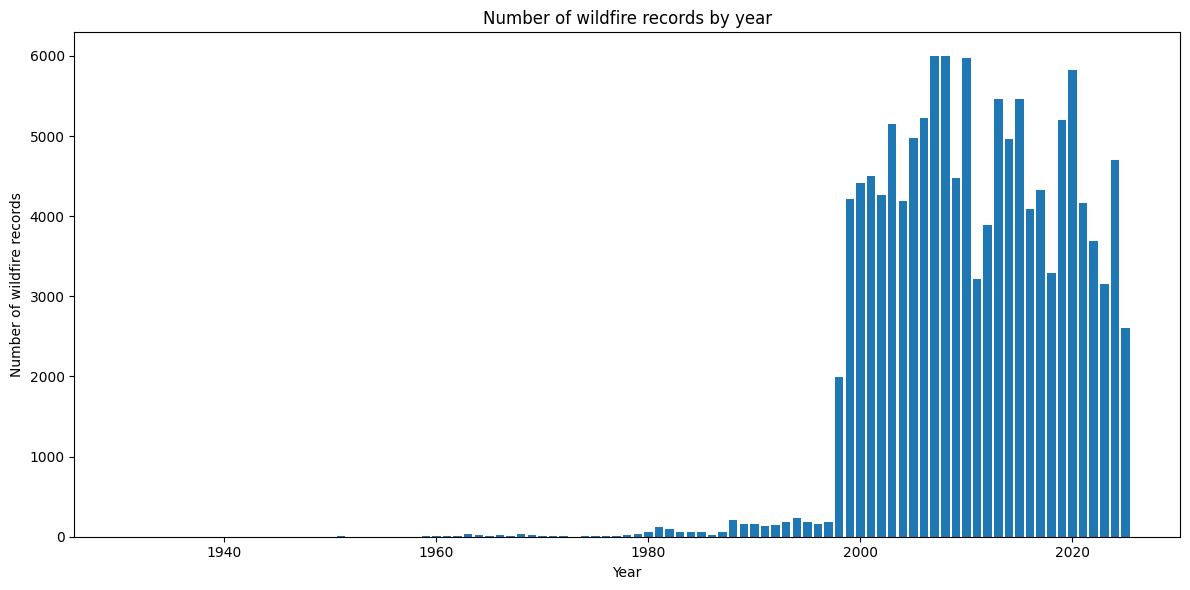

In [11]:
year_counts = df["Year"].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 6))
plt.bar(year_counts.index, year_counts.values)

plt.xlabel("Year")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records by year")

plt.tight_layout()
plt.show()

<BarContainer object of 28 artists>

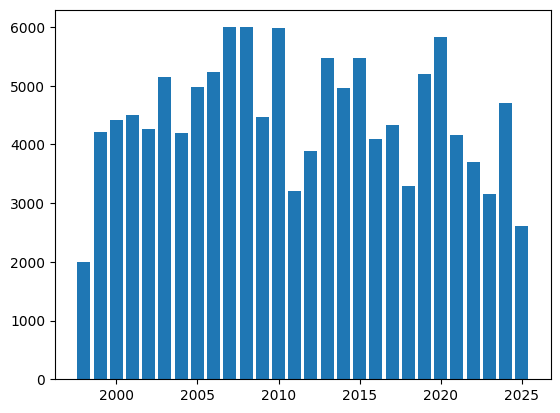

In [12]:
year_counts = df[(df["Year"]>=1998)]["Year"].value_counts().sort_index()
plt.bar(year_counts.index, year_counts.values)

In [13]:
df = df[df["Year"] >= 1998]

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 125407 entries, 0 to 128019
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        90544 non-null   float64
 1   RH          90510 non-null   float64
 2   WS          90580 non-null   float64
 3   WD          89707 non-null   float64
 4   FFMC        39741 non-null   float64
 5   ISI         39741 non-null   float64
 6   FWI         39741 non-null   float64
 7   Precip24hr  85638 non-null   float64
 8   NoRain1     94104 non-null   float64
 9   NoRain2     93799 non-null   float64
 10  NoRain3     93526 non-null   float64
 11  FuelType    125407 non-null  object 
 12  FuelClass   125407 non-null  object 
 13  LandCvr     125407 non-null  object 
 14  Elev        124555 non-null  float64
 15  Slope       124628 non-null  float64
 16  AspectDeg   121536 non-null  float64
 17  Landform    125407 non-null  object 
 18  Lat         125407 non-null  float64
 19  Lon    

In [15]:
df.describe()

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Slope,AspectDeg,Lat,Lon,Day,Month,Hour,Year,SOI,AreaHa
count,90544.00,90510.00,90580.00,89707.00,39741.00,39741.00,39741.00,85638.00,94104.00,93799.00,...,124628.00,121536.00,125407.00,125407.00,125407.00,125407.00,122538.00,125407.00,125364.00,125407.00
mean,16.99,65.91,3.96,185.30,77.19,4.02,7.55,0.85,12.48,16.21,...,2.49,175.01,-40.05,173.95,15.31,6.28,14.37,2011.33,2.08,1.16
std,5.51,17.99,2.96,108.32,14.94,5.46,9.11,3.89,19.42,19.51,...,4.16,92.71,3.20,4.61,8.95,4.03,5.22,7.62,10.06,39.59
min,-32.90,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-47.21,-176.61,1.00,1.00,0.00,1998.00,-28.60,-0.00
25%,13.50,54.00,1.90,80.00,77.23,1.47,1.28,0.00,2.00,4.00,...,0.00,99.06,-43.35,172.66,7.00,2.00,12.00,2005.00,-5.50,0.00
50%,17.20,66.00,3.30,209.00,81.98,2.59,4.72,0.00,4.00,8.00,...,1.00,164.95,-39.59,174.70,15.00,5.00,15.00,2011.00,1.30,0.00
75%,20.90,79.00,5.14,274.00,84.68,4.43,10.22,0.20,10.00,17.00,...,3.00,255.45,-37.08,175.31,23.00,11.00,18.00,2018.00,9.40,0.00
max,48.00,100.00,38.52,360.00,101.00,122.32,102.85,194.40,90.00,90.00,...,43.00,359.74,-34.16,178.97,31.00,12.00,23.00,2025.00,27.10,6159.00


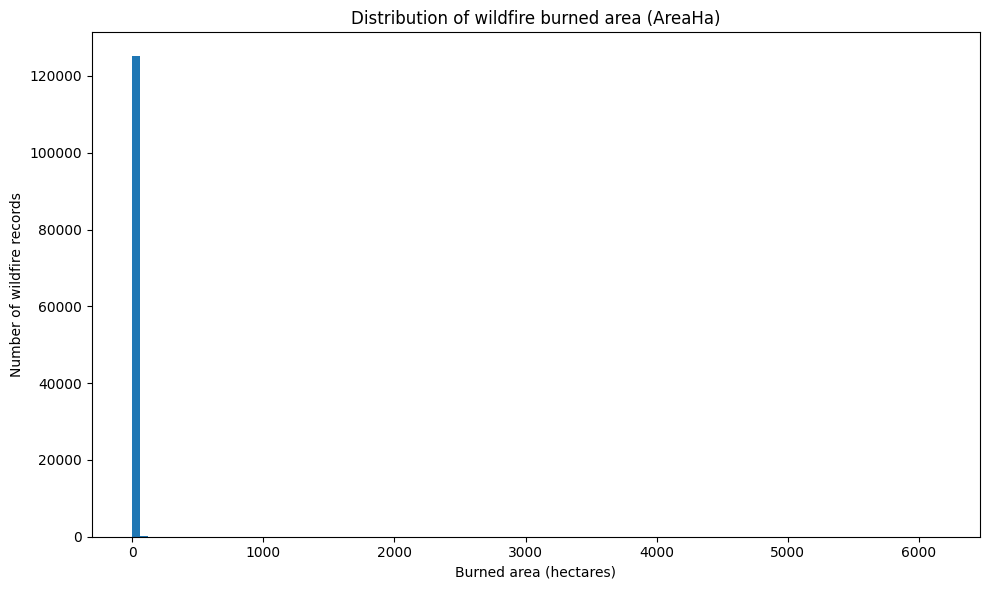

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(df["AreaHa"].dropna(), bins=100)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Distribution of wildfire burned area (AreaHa)")

plt.tight_layout()
plt.show()

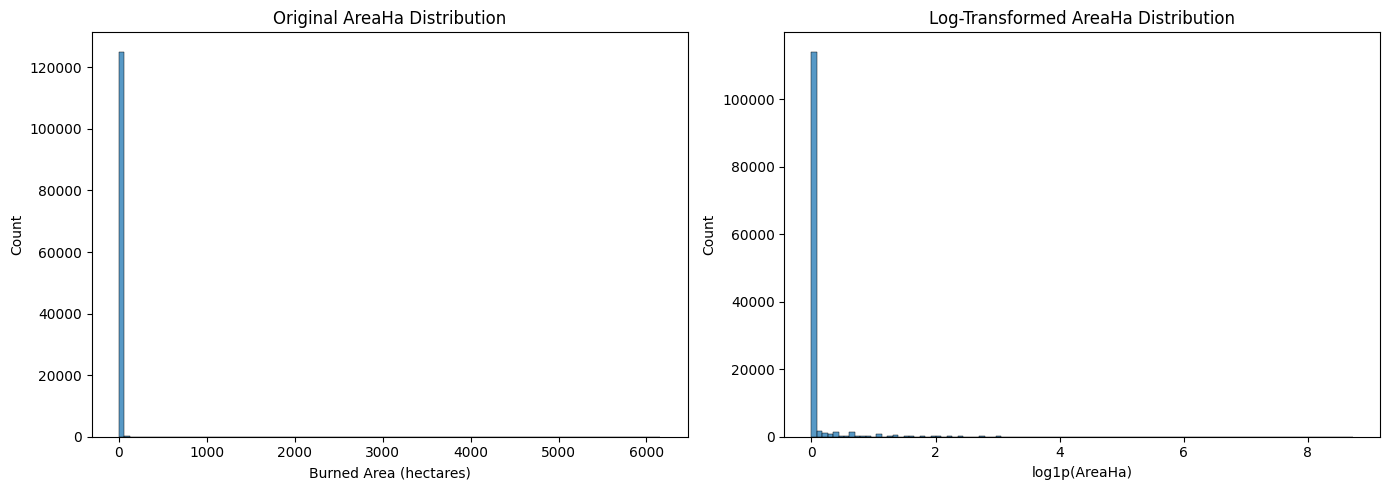

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Log-transform for visualisation only
log_area = np.log1p(df["AreaHa"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["AreaHa"], bins=100, ax=axes[0])
axes[0].set_title("Original AreaHa Distribution")
axes[0].set_xlabel("Burned Area (hectares)")

sns.histplot(log_area, bins=100, ax=axes[1])
axes[1].set_title("Log-Transformed AreaHa Distribution")
axes[1].set_xlabel("log1p(AreaHa)")

plt.tight_layout()
plt.show()

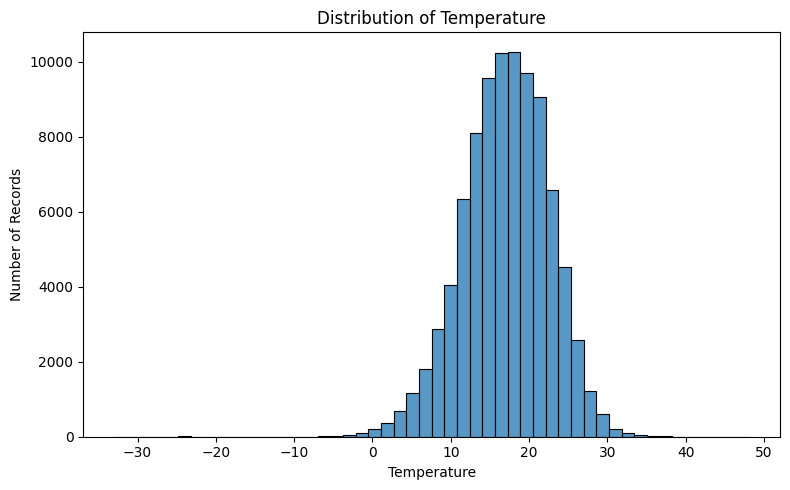

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Temp", bins=50)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

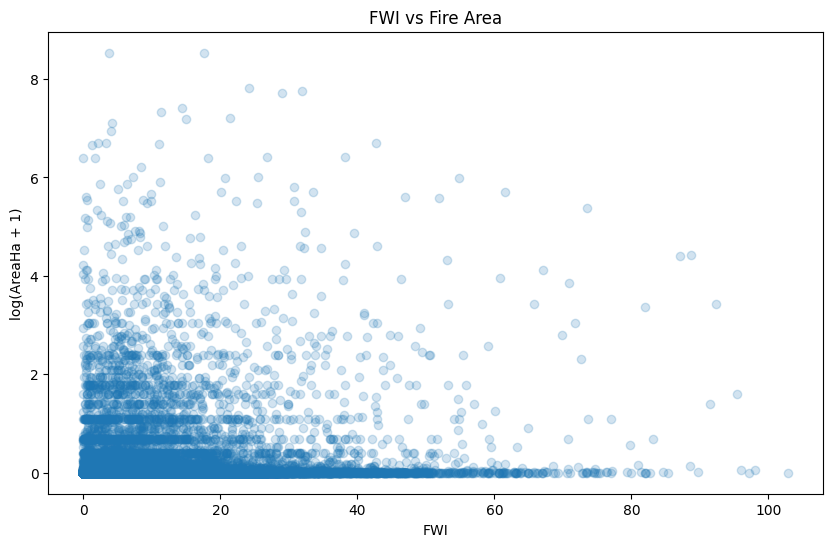

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["FWI"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("FWI")
plt.ylabel("log(AreaHa + 1)")
plt.title("FWI vs Fire Area")

plt.show()

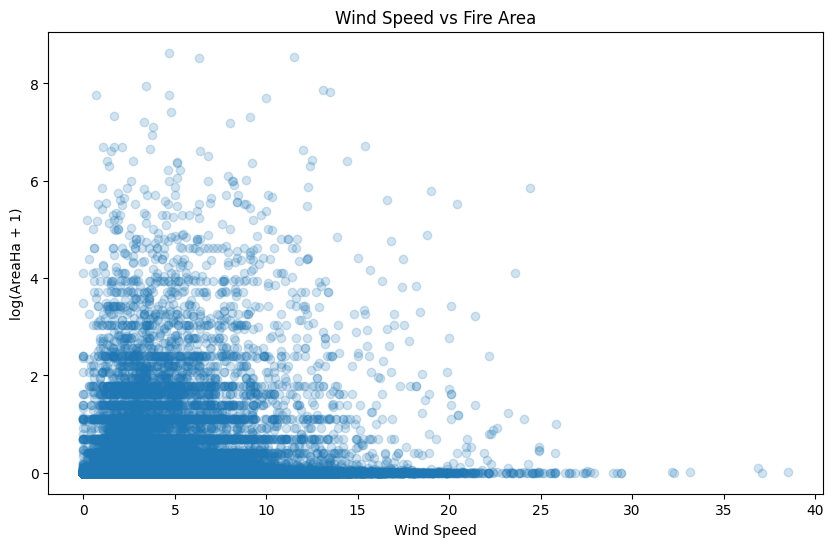

In [20]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["WS"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Wind Speed")
plt.ylabel("log(AreaHa + 1)")
plt.title("Wind Speed vs Fire Area")
plt.show()

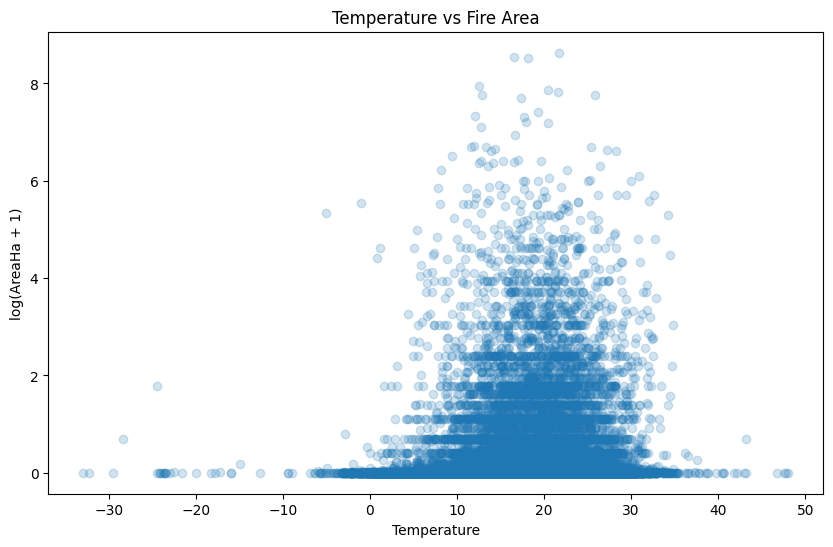

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Temp"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Temperature")
plt.ylabel("log(AreaHa + 1)")
plt.title("Temperature vs Fire Area")
plt.show()

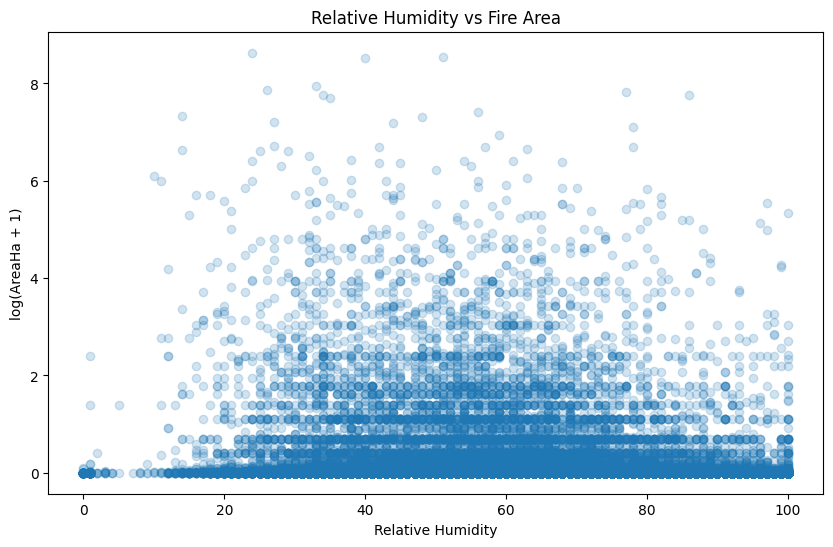

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["RH"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Relative Humidity")
plt.ylabel("log(AreaHa + 1)")
plt.title("Relative Humidity vs Fire Area")
plt.show()

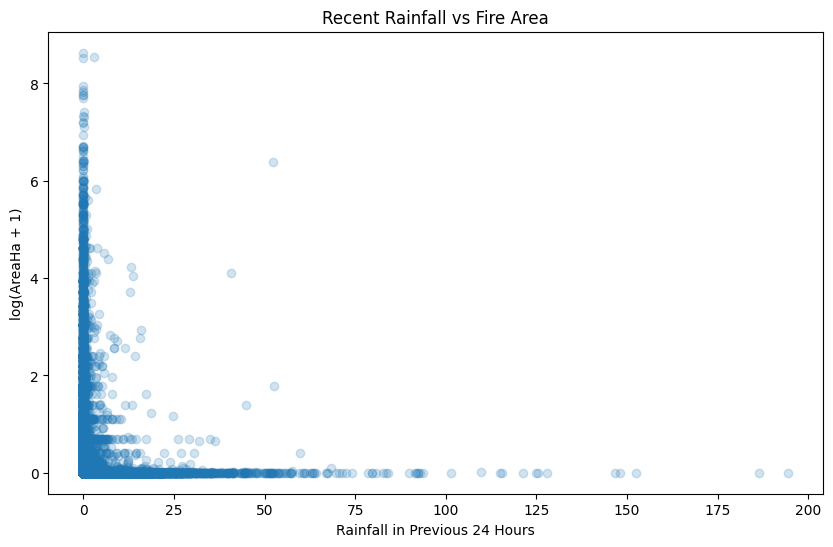

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Precip24hr"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Rainfall in Previous 24 Hours")
plt.ylabel("log(AreaHa + 1)")
plt.title("Recent Rainfall vs Fire Area")
plt.show()

In [24]:
# df[["Precip24hr", "AreaHa"]].skew()


log_df = np.log1p(df[["Precip24hr", "AreaHa"]])

log_df.skew()

Precip24hr   3.03
AreaHa       7.64
dtype: float64

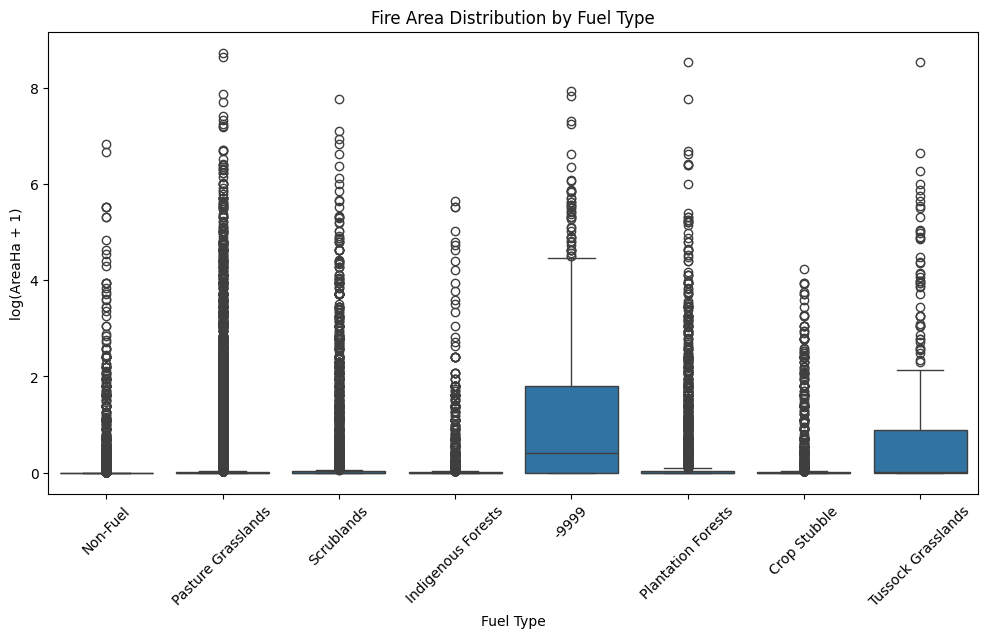

In [25]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="FuelType",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Fuel Type")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Fuel Type")
plt.xticks(rotation=45)
plt.show()

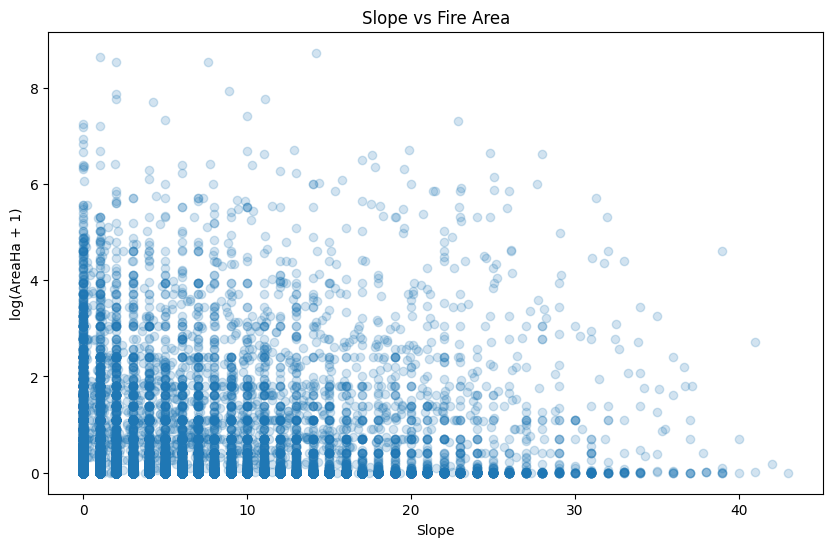

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Slope"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Slope")
plt.ylabel("log(AreaHa + 1)")
plt.title("Slope vs Fire Area")
plt.show()

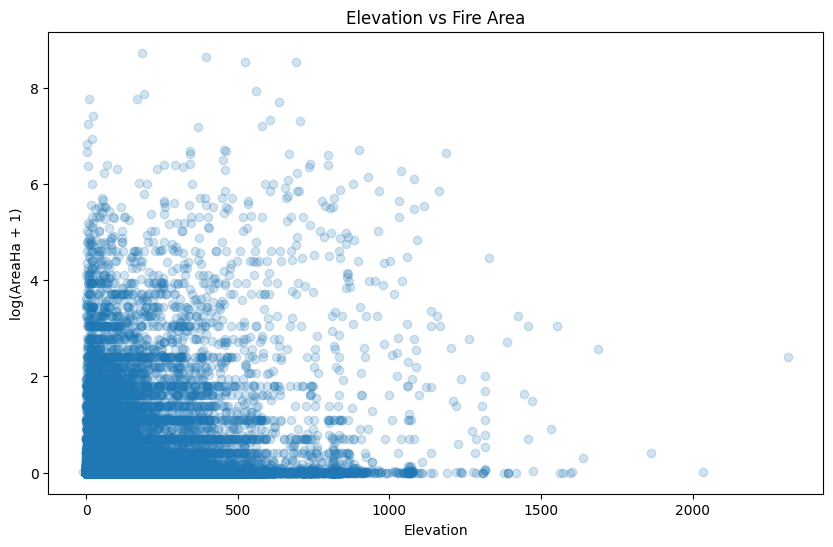

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Elev"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Elevation")
plt.ylabel("log(AreaHa + 1)")
plt.title("Elevation vs Fire Area")
plt.show()

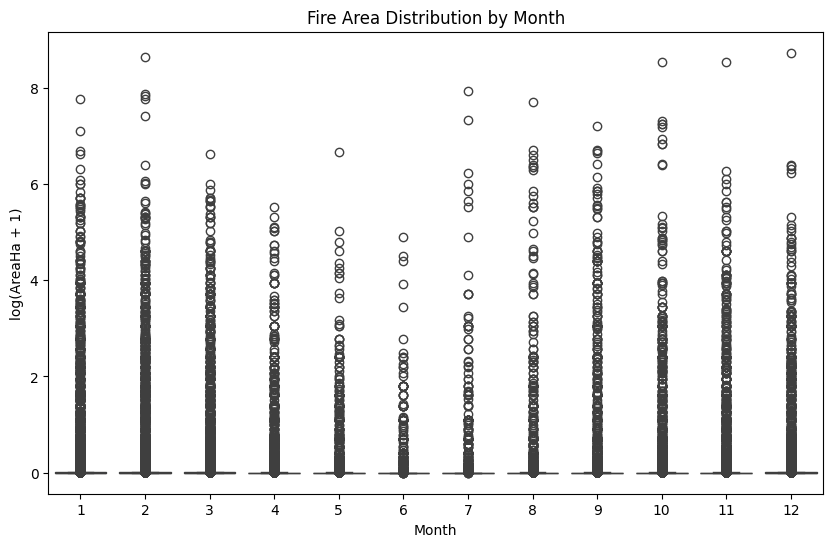

In [28]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Month",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Month")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Month")
plt.show()

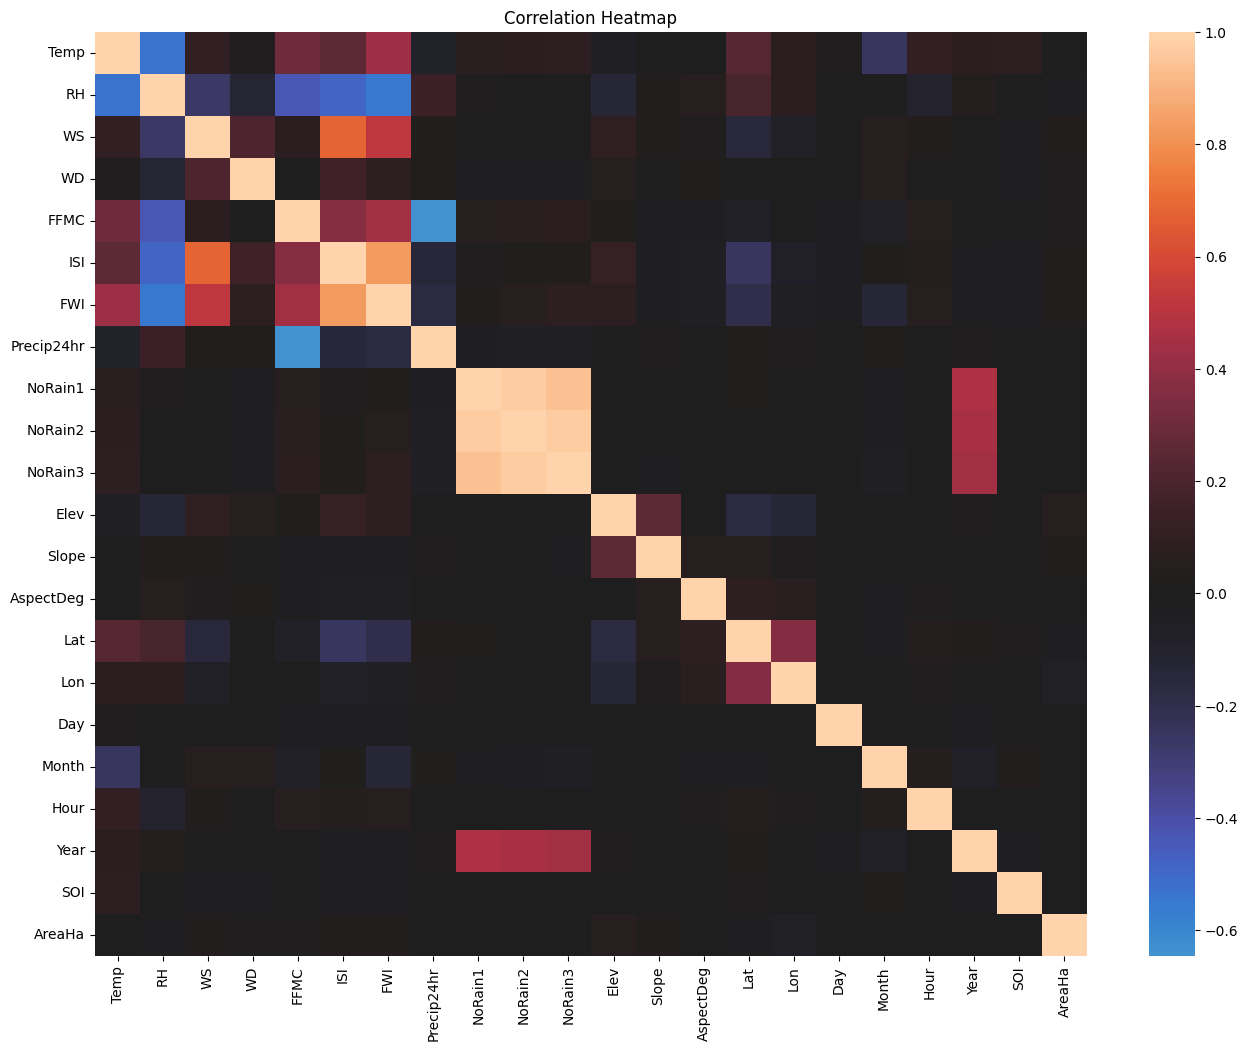

In [29]:
numeric_cols = df.select_dtypes(include="number").columns

plt.figure(figsize=(16, 12))

sns.heatmap(
    df[numeric_cols].corr(),
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

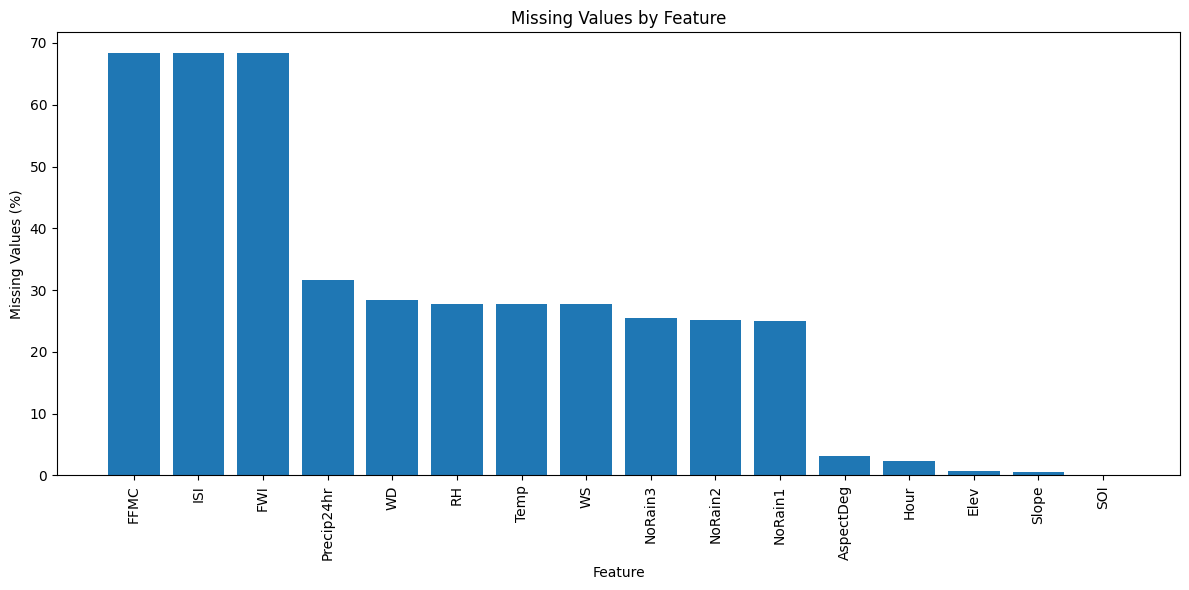

In [30]:
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12,6))
plt.bar(missing.index, missing.values)

plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

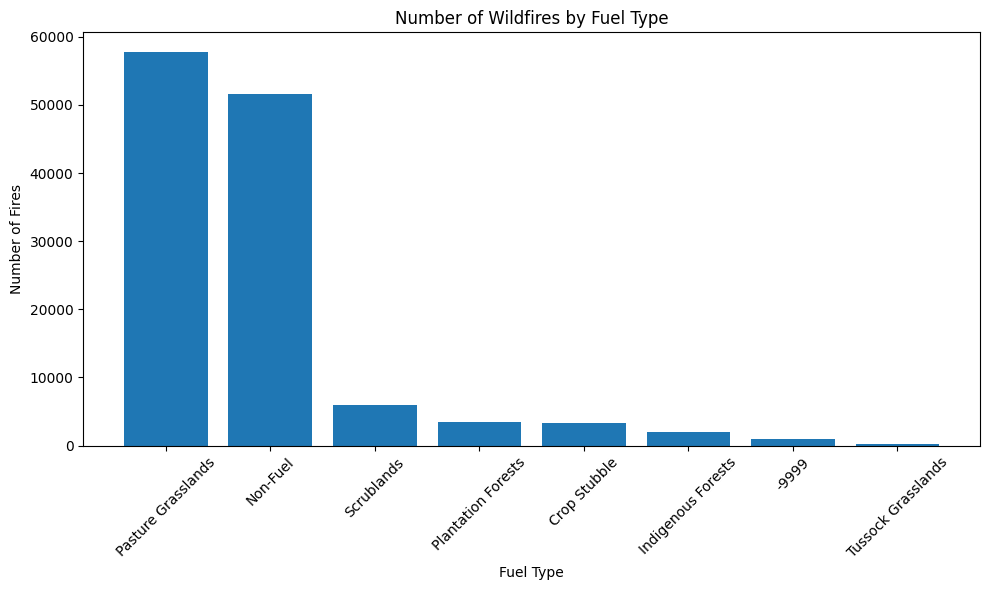

In [31]:
fuel_counts = df["FuelType"].value_counts()

plt.figure(figsize=(10,6))
plt.bar(fuel_counts.index, fuel_counts.values)

plt.xlabel("Fuel Type")
plt.ylabel("Number of Fires")
plt.title("Number of Wildfires by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

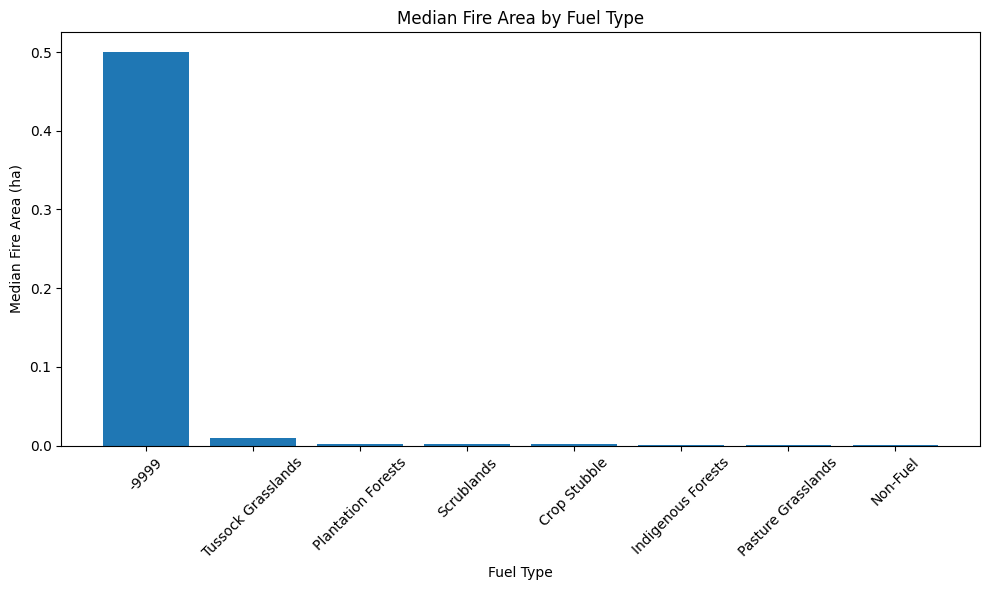

In [32]:
fuel_median = (
    df.groupby("FuelType")["AreaHa"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
plt.bar(fuel_median.index, fuel_median.values)

plt.xlabel("Fuel Type")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

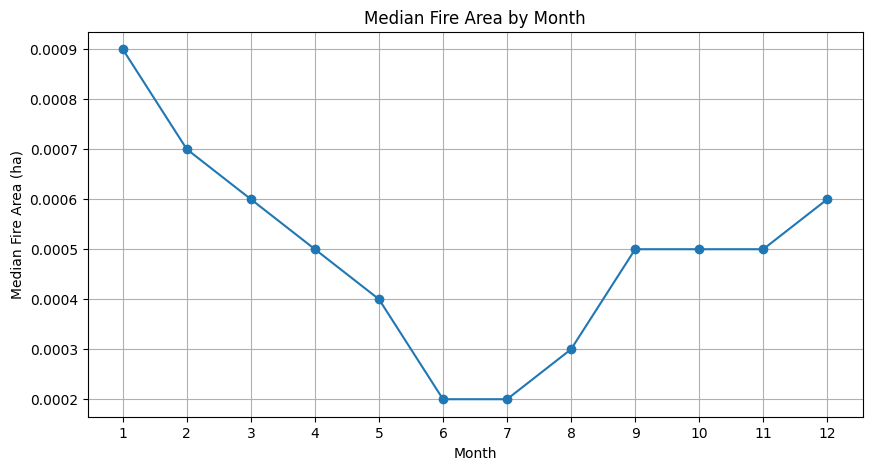

In [33]:
monthly_median = (
    df.groupby("Month")["AreaHa"]
    .median()
)

plt.figure(figsize=(10,5))
plt.plot(
    monthly_median.index,
    monthly_median.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Month")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

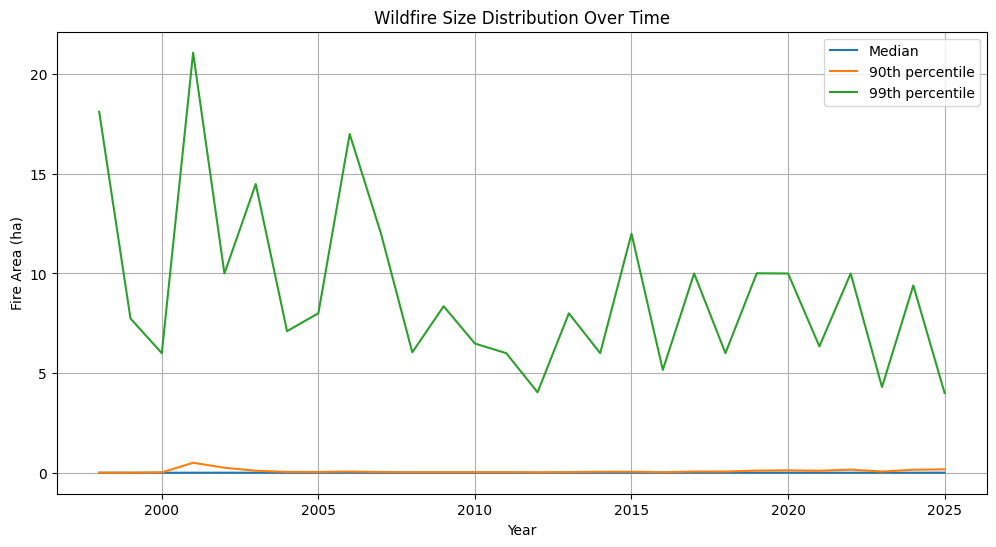

In [34]:
year_area = df.groupby("Year")["AreaHa"].agg(
    median="median",
    p90=lambda x: x.quantile(0.90),
    p99=lambda x: x.quantile(0.99)
)

plt.figure(figsize=(12,6))

plt.plot(year_area.index, year_area["median"], label="Median")
plt.plot(year_area.index, year_area["p90"], label="90th percentile")
plt.plot(year_area.index, year_area["p99"], label="99th percentile")

plt.xlabel("Year")
plt.ylabel("Fire Area (ha)")
plt.title("Wildfire Size Distribution Over Time")
plt.legend()
plt.grid(True)
plt.show()

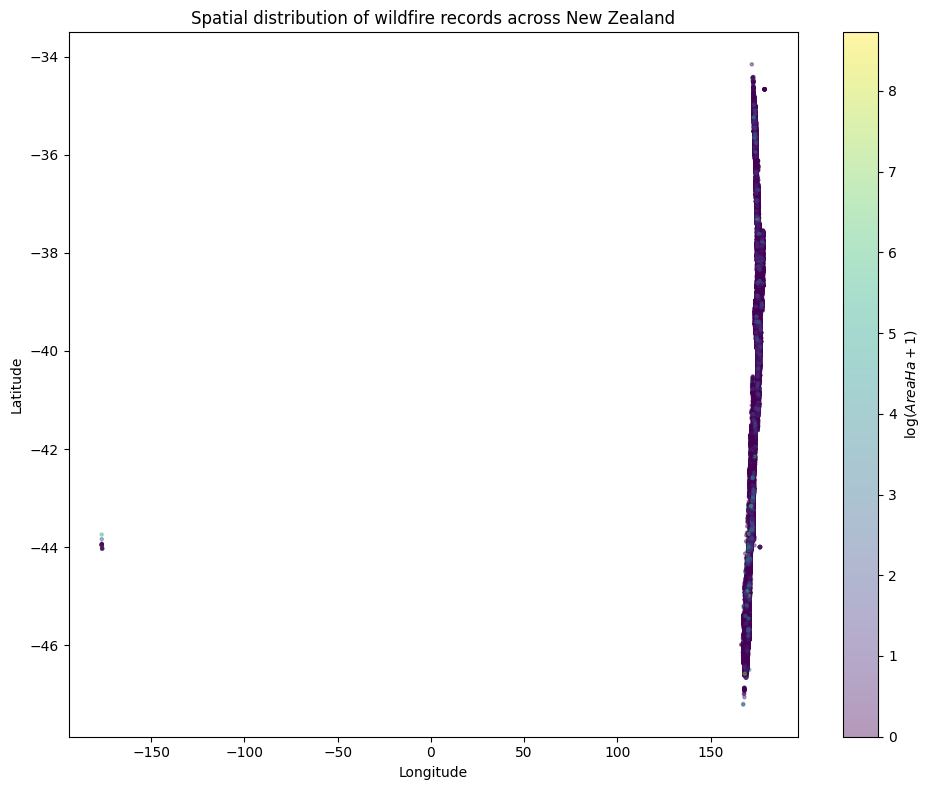

In [35]:
spatial_df = df[
    df["Lon"].notna() &
    df["Lat"].notna() &
    df["AreaHa"].notna()
].copy()

# Log-transform burned area for visualisation
spatial_df["LogArea"] = np.log1p(spatial_df["AreaHa"])

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_df["Lon"],
    spatial_df["Lat"],
    c=spatial_df["LogArea"],
    s=5,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial distribution of wildfire records across New Zealand")

cbar = plt.colorbar(scatter)
cbar.set_label(r"$\log(AreaHa + 1)$")

plt.tight_layout()
plt.show()

C:\Users\simra\AppData\Local\Temp\ipykernel_36432\1104798615.py:32: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


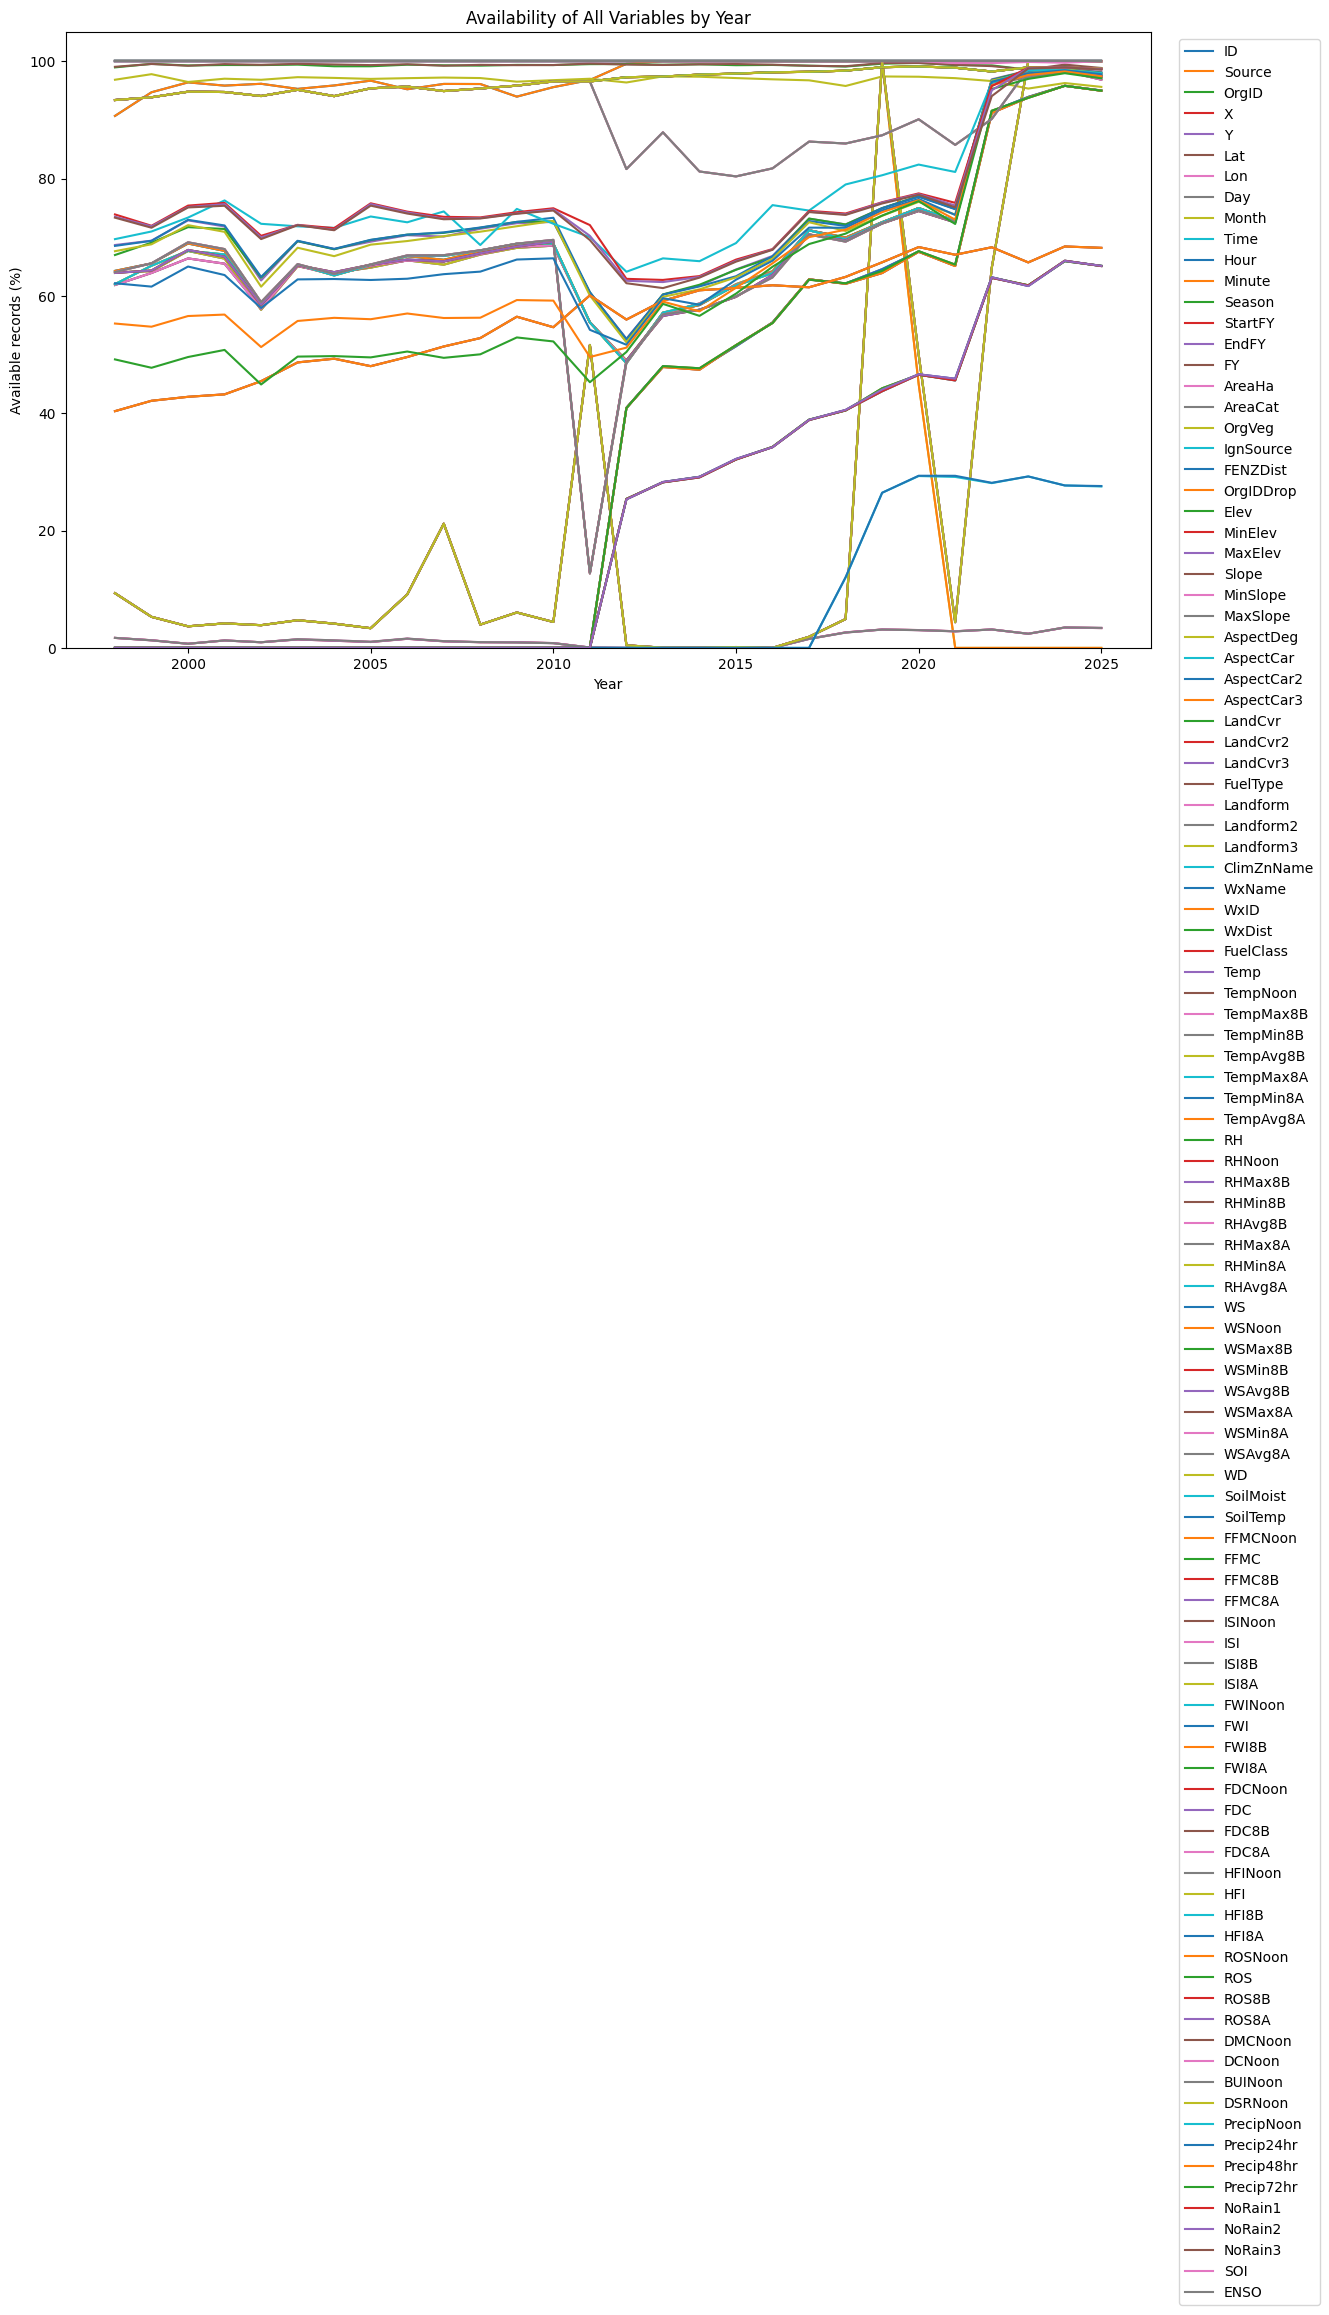

In [36]:
raw_df.replace(-9999, np.nan, inplace=True)
features = [col for col in raw_df.columns if col != "Year"]
df_filtered = raw_df[raw_df["Year"] >= 1998].copy()

# Calculate percentage of available values for each feature by year
availability = (
    df_filtered.groupby("Year")[features]
      .apply(lambda x: x.notna().mean() * 100)
)

# Plot
plt.figure(figsize=(14, 8))

for feature in features:
    plt.plot(
        availability.index,
        availability[feature],
        label=feature
    )

plt.xlabel("Year")
plt.ylabel("Available records (%)")
plt.title("Availability of All Variables by Year")

plt.ylim(0, 105)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=1
)

plt.tight_layout()
plt.show()

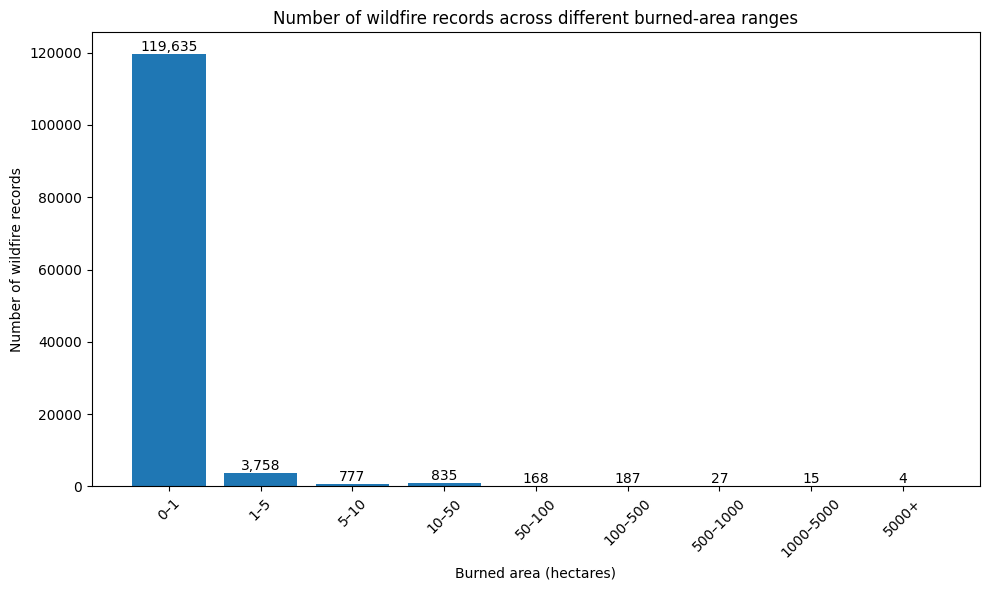

In [37]:
bins = [0, 1, 5, 10, 50, 100, 500, 1000, 5000, float("inf")]
labels = [
    "0–1",
    "1–5",
    "5–10",
    "10–50",
    "50–100",
    "100–500",
    "500–1000",
    "1000–5000",
    "5000+"
]

# Group wildfire records by burned-area range
fire_size_ranges = pd.cut(
    df["AreaHa"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
size_counts = fire_size_ranges.value_counts().sort_index()

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    size_counts.index,
    size_counts.values
)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records across different burned-area ranges")

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

((array([-4.39545038, -4.19880644, -4.09192566, ...,  4.09192566,
          4.19880644,  4.39545038], shape=(125407,)),
  array([-1.0000e-04,  0.0000e+00,  0.0000e+00, ...,  5.0888e+03,
          5.6000e+03,  6.1590e+03], shape=(125407,))),
 (np.float64(3.766006620837243),
  np.float64(1.1567848983426763),
  np.float64(0.0951196260656166)))

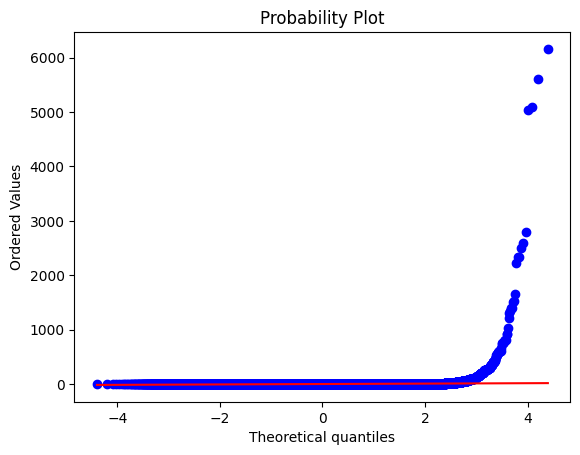

In [38]:
# sns.distplot(df["AreaHa"])

stats.probplot(df["AreaHa"], dist="norm", plot=plt)

#### Preprocessing on Target Variable (AreaHa)

In [39]:
print("Missing target values:", df["AreaHa"].isna().sum())
print("Negative target values:", (df["AreaHa"] < 0).sum())
print("Zero-area records:", (df["AreaHa"] == 0).sum())

display(df.loc[df["AreaHa"] < 0, ["AreaHa"]])

Missing target values: 0
Negative target values: 1
Zero-area records: 27405


,AreaHa
97794,-0.00


In [40]:
# Inspect the original WOD record
negative_index = df[df["AreaHa"] < 0].index

display(
    raw_df.loc[
        raw_df["AreaHa"] < 0,
        ["ID", "Year", "Month", "FuelType", "AreaHa"]
    ]
)

,ID,Year,Month,FuelType,AreaHa
97794,WOD68255,2018,11,Non-Fuel,-0.00


In [41]:
df = df[df["AreaHa"].notna() & (df["AreaHa"] >= 0)]
df.shape, raw_df.shape

((125406, 28), (128020, 109))

In [42]:
# Compare zero and positive burned-area records
print("Zero-area records:", (df["AreaHa"] == 0).sum())
print("Positive-area records:", (df["AreaHa"] > 0).sum())

# Check zero-area records by year
zero_area_by_year = (
    df[df["AreaHa"] == 0]
    .groupby("Year")
    .size()
)

display(zero_area_by_year)

Zero-area records: 27405
Positive-area records: 98001


Year
1998    1862
1999    3949
2000    2895
2001    1308
2002    1013
2003    1613
2004    1429
2005    1088
2006    1175
2007    1317
2008    1255
2009    1002
2010    1198
2011     701
2012     838
2013    1056
2014    1123
2015    1158
2016     880
2017     483
2018       6
2019      21
2020       2
2021       2
2022      28
2024       2
2025       1
dtype: int64

In [43]:
df["AreaHa"].describe()

count   125406.00
mean         1.16
std         39.59
min          0.00
25%          0.00
50%          0.00
75%          0.00
max       6159.00
Name: AreaHa, dtype: float64

In [44]:
print("AreaHa summary:")
print(df["AreaHa"].describe())

print("\nSkewness of original AreaHa:",
      df["AreaHa"].skew())

print("\nSkewness of log1p(AreaHa):",
      np.log1p(df["AreaHa"]).skew())

print("\nLargest 10 recorded fire areas:")
print(df["AreaHa"].nlargest(10).to_list())

AreaHa summary:
count   125406.00
mean         1.16
std         39.59
min          0.00
25%          0.00
50%          0.00
75%          0.00
max       6159.00
Name: AreaHa, dtype: float64

Skewness of original AreaHa: 102.20586764292612

Skewness of log1p(AreaHa): 7.635972531329059

Largest 10 recorded fire areas:
[6159.0, 5600.0, 5088.8, 5033.0, 2800.0, 2600.0, 2500.0, 2338.0, 2333.8, 2226.6]


#### Train-Test Split

In [45]:
df = df[df["Year"] >= 1998]

In [46]:
years = np.sort(df["Year"].unique())

# Reserve the final 20% of years for testing
split_year_idx = int(len(years) * 0.80)
test_start_year = years[split_year_idx]

train_df = df[df["Year"] < test_start_year].copy()
test_df = df[df["Year"] >= test_start_year].copy()

target = "AreaHa"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

#### Implementing ML Pipeline

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer

##### 1) Keeping Only Useful Features

In [48]:
features = [
    # Weather at detection
    "Temp", "RH", "WS", "WD",
    # Fire-weather indices
    "FFMC", "ISI",
    # Recent rainfall and drying
    "Precip24hr", "NoRain1", "NoRain2", "NoRain3",
    # Fuel and land cover
    "FuelClass", "LandCvr",
    # Topography
    "Elev", "Slope", "AspectDeg", "Landform",
    # Location and time
    "Lat", "Lon", "FENZDist",
    "Day", "Month", "Hour", "Year",
    # Climate
    "SOI", "ENSO"
]

trf1 = FunctionTransformer(
    # lambda x: x[features].copy()
    lambda x: x.copy()
)

X_train_temp = trf1.fit_transform(X_train)
X_train_temp.sample(1)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Landform,Lat,Lon,FENZDist,Day,Month,Hour,Year,SOI,ENSO
26697,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Valley,-39.56,174.30,Taranaki,11,3,19.00,2010,-10.60,Neutral


##### 2) Caping inaccurate Values

In [49]:
df.describe()

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Slope,AspectDeg,Lat,Lon,Day,Month,Hour,Year,SOI,AreaHa
count,90543.00,90509.00,90579.00,89706.00,39740.00,39740.00,39740.00,85637.00,94103.00,93798.00,...,124627.00,121535.00,125406.00,125406.00,125406.00,125406.00,122537.00,125406.00,125363.00,125406.00
mean,16.99,65.91,3.96,185.30,77.19,4.02,7.55,0.85,12.48,16.21,...,2.49,175.01,-40.05,173.95,15.31,6.28,14.37,2011.33,2.08,1.16
std,5.51,17.99,2.96,108.32,14.94,5.46,9.11,3.89,19.42,19.51,...,4.16,92.71,3.20,4.61,8.95,4.03,5.22,7.62,10.06,39.59
min,-32.90,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-47.21,-176.61,1.00,1.00,0.00,1998.00,-28.60,0.00
25%,13.50,54.00,1.90,80.00,77.23,1.47,1.28,0.00,2.00,4.00,...,0.00,99.06,-43.35,172.66,7.00,2.00,12.00,2005.00,-5.50,0.00
50%,17.20,66.00,3.30,209.00,81.98,2.59,4.72,0.00,4.00,8.00,...,1.00,164.95,-39.59,174.70,15.00,5.00,15.00,2011.00,1.30,0.00
75%,20.90,79.00,5.14,274.00,84.68,4.43,10.22,0.20,10.00,17.00,...,3.00,255.45,-37.08,175.31,23.00,11.00,18.00,2018.00,9.40,0.00
max,48.00,100.00,38.52,360.00,101.00,122.32,102.85,194.40,90.00,90.00,...,43.00,359.74,-34.16,178.97,31.00,12.00,23.00,2025.00,27.10,6159.00


In [50]:
trf2 = FunctionTransformer(
    lambda X: X.assign(
        # Weather at detection
        Temp=np.where(
            (X["Temp"] >= -33) & (X["Temp"] <= 48),
            X["Temp"], np.nan
        ),
        RH=np.where(
            (X["RH"] >= 0) & (X["RH"] <= 100),
            X["RH"], np.nan
        ),
        WS=np.where(
            (X["WS"] >= 0) & (X["WS"] <= 150),
            X["WS"], np.nan
        ),
        WD=np.where(
            (X["WD"] >= 0) & (X["WD"] <= 360),
            X["WD"], np.nan
        ),

        # Fire-weather indices
        FFMC=np.where(
            (X["FFMC"] >= 0) & (X["FFMC"] <= 101),
            X["FFMC"], np.nan
        ),
        ISI=np.where(
            (X["ISI"] >= 0) & (X["ISI"] <= 100),
            X["ISI"], np.nan
        ),
        # FWI=np.where(
        #     (X["FWI"] >= 0) & (X["FWI"] <= 150),
        #     X["FWI"], np.nan
        # ),

        # Recent rainfall and drying
        Precip24hr=np.where(
            X["Precip24hr"] >= 0,
            X["Precip24hr"], np.nan
        ),
        NoRain1=np.where(
            X["NoRain1"] >= 0,
            X["NoRain1"], np.nan
        ),
        NoRain2=np.where(
            X["NoRain2"] >= 0,
            X["NoRain2"], np.nan
        ),
        NoRain3=np.where(
            X["NoRain3"] >= 0,
            X["NoRain3"], np.nan
        ),

        # Topography
        Elev=np.where(
            X["Elev"] >= -500,
            X["Elev"], np.nan
        ),
        Slope=np.where(
            (X["Slope"] >= 0) & (X["Slope"] <= 90),
            X["Slope"], np.nan
        ),
        AspectDeg=np.where(
            (X["AspectDeg"] >= 0) & (X["AspectDeg"] <= 360),
            X["AspectDeg"], np.nan
        ),

        # Location
        Lat=np.where(
            (X["Lat"] >= -90) & (X["Lat"] <= 90),
            X["Lat"], np.nan
        ),
        Lon=np.where(
            (X["Lon"] >= -180) & (X["Lon"] <= 180),
            X["Lon"], np.nan
        ),

        # Time
        Day=np.where(
            (X["Day"] >= 1) & (X["Day"] <= 31),
            X["Day"], np.nan
        ),
        Month=np.where(
            (X["Month"] >= 1) & (X["Month"] <= 12),
            X["Month"], np.nan
        ),
        Hour=np.where(
            (X["Hour"] >= 0) & (X["Hour"] <= 23),
            X["Hour"], np.nan
        ),
        Year=np.clip(X["Year"], 1998, 2025),
    )
)

X_train_temp = trf2.fit_transform(X_train_temp)

X_train_temp.shape, X_train.shape

((101263, 27), (101263, 27))

##### 3) Handle Missing Values

In [51]:
# Identify numerical and categorical features
numeric_cols = X_train_temp.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_cols)
print("\nCategorical features:", categorical_cols)

Numerical features: ['Temp', 'RH', 'WS', 'WD', 'FFMC', 'ISI', 'FWI', 'Precip24hr', 'NoRain1', 'NoRain2', 'NoRain3', 'Elev', 'Slope', 'AspectDeg', 'Lat', 'Lon', 'Day', 'Month', 'Hour', 'Year', 'SOI']

Categorical features: ['FuelType', 'FuelClass', 'LandCvr', 'Landform', 'FENZDist', 'ENSO']


In [52]:
# Handling missing values
trf3 = ColumnTransformer(
    transformers=[
        # Handling missing values on numerical features
        (
            "trf_3_1",
            SimpleImputer(strategy="median"),
            numeric_cols
        ),

        # Handling missing values on categorical features
        (
            "trf_3_2",
            SimpleImputer(strategy="most_frequent"),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

trf3.set_output(transform="pandas")

X_train_temp = trf3.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Month,Hour,Year,SOI,FuelType,FuelClass,LandCvr,Landform,FENZDist,ENSO
66960,17.00,66.00,3.30,212.00,81.91,2.57,4.62,0.00,3.00,7.00,...,12.00,11.00,2011.00,23.00,Pasture Grasslands,Grass,High Producing Exotic Grassland,Valley,Waikato,La Nina
80744,17.00,66.00,3.30,212.00,81.91,2.57,4.62,0.00,3.00,7.00,...,11.00,11.00,2014.00,-10.00,Pasture Grasslands,Grass,High Producing Exotic Grassland,Valley,Nelson Marlborough,El Nino
87933,17.20,51.00,3.80,91.00,81.91,2.57,4.62,0.00,21.00,22.00,...,3.00,13.00,2016.00,-4.70,Pasture Grasslands,Grass,High Producing Exotic Grassland,Valley,Nelson Marlborough,El Nino
45356,15.40,74.00,1.40,65.00,81.91,2.57,4.62,0.00,7.00,13.00,...,2.00,22.00,2006.00,0.10,Non-Fuel,Non Fuel,Built-up Area (settlement),Valley,Canterbury,Neutral
83216,18.00,53.00,5.77,147.00,81.85,3.99,9.71,0.20,5.00,7.00,...,3.00,12.00,2015.00,-11.20,Non-Fuel,Non Fuel,Built-up Area (settlement),Valley,Tairawhiti,El Nino


##### 4) Handling Highly Skewed Features

In [53]:
skew_features = [
    "Precip24hr", "ISI", "NoRain1",
    "NoRain2", "NoRain3", "WS"
]

numeric_features = X_train_temp[skew_features].select_dtypes(
    include=np.number
)

skew_values = numeric_features.skew().sort_values(
    ascending=False
)

skew_values

Precip24hr   18.55
ISI          11.67
NoRain1       5.23
NoRain2       4.09
NoRain3       3.29
WS            2.40
dtype: float64

In [54]:
trf4 = FunctionTransformer(
    lambda X: X.assign(
        Precip24hr=np.log1p(X["Precip24hr"]),
        ISI=np.log1p(X["ISI"]),
        NoRain1=np.log1p(X["NoRain1"]),
        NoRain2=np.log1p(X["NoRain2"]),
        NoRain3=np.log1p(X["NoRain3"]),
        # FWI=np.log1p(X["FWI"]),
        WS=np.log1p(X["WS"])
    )
)

X_train_temp = trf4.fit_transform(X_train_temp)

X_train_temp[skew_features].skew().sort_values(
    ascending=False
)

Precip24hr    3.95
ISI           1.91
NoRain1       0.48
NoRain2       0.35
NoRain3       0.24
WS           -0.15
dtype: float64

##### 5) Applying Circular Encoding

In [55]:
trf5 = FunctionTransformer(
    lambda X: X.assign(
        WD_sin=np.sin(np.deg2rad(X["WD"])),
        WD_cos=np.cos(np.deg2rad(X["WD"])),
        AspectDeg_sin=np.sin(np.deg2rad(X["AspectDeg"])),
        AspectDeg_cos=np.cos(np.deg2rad(X["AspectDeg"]))
    ).drop(columns=["WD", "AspectDeg"])
)

X_train_temp = trf5.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((101263, 29), (101263, 27))

##### 6) Encoding Month and Hour cyclically

In [56]:
trf6 = FunctionTransformer(
    lambda X: X.assign(
        Month_sin=np.sin(2 * np.pi * (X["Month"] - 1) / 12),
        Month_cos=np.cos(2 * np.pi * (X["Month"] - 1) / 12),
        Hour_sin=np.sin(2 * np.pi * X["Hour"] / 24),
        Hour_cos=np.cos(2 * np.pi * X["Hour"] / 24)
    ).drop(columns=["Month", "Hour"])
)


X_train_temp = trf6.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((101263, 31), (101263, 27))

##### 7) Encoding Categorical Features

In [57]:
# Identify categorical columns after trf5
categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_cols

['FuelType', 'FuelClass', 'LandCvr', 'Landform', 'FENZDist', 'ENSO']

In [58]:
# One-hot encoding
trf7 = ColumnTransformer(
    transformers=[
        (
            "trf_7_1",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

trf7.set_output(transform="pandas")

X_train_temp = trf7.fit_transform(X_train_temp)
X_train_temp.sample(5)

,FuelType_-9999,FuelType_Crop Stubble,FuelType_Indigenous Forests,FuelType_Non-Fuel,FuelType_Pasture Grasslands,FuelType_Plantation Forests,FuelType_Scrublands,FuelType_Tussock Grasslands,FuelClass_-9999,FuelClass_Forest,...,Year,SOI,WD_sin,WD_cos,AspectDeg_sin,AspectDeg_cos,Month_sin,Month_cos,Hour_sin,Hour_cos
17024,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,...,2007.00,5.40,0.16,-0.99,0.01,-1.00,-1.00,-0.00,-0.87,-0.50
42187,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2003.00,9.30,-0.95,0.31,1.00,-0.05,-0.50,0.87,-0.50,0.87
36564,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2000.00,16.80,-0.53,-0.85,-0.09,1.00,1.00,0.00,0.00,1.00
79289,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,...,2014.00,-11.40,-0.66,0.75,-0.55,0.83,-0.50,-0.87,-0.26,-0.97
37745,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2001.00,11.90,-1.00,-0.02,-0.89,0.45,0.50,0.87,-1.00,-0.00


##### 8) Scaling features

In [59]:
numeric_cols = [
    col for col in X_train_temp.columns
    if col not in ["FFMC", "ISI", "FWI"]
    and pd.api.types.is_numeric_dtype(X_train_temp[col])
]

trf8 = ColumnTransformer(
    transformers=[
        (
            "trf_8_1",
            StandardScaler(),
            numeric_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf8.set_output(transform="pandas")

X_train_temp = trf8.fit_transform(X_train_temp)
X_train_temp.sample(5)

,FuelType_-9999,FuelType_Crop Stubble,FuelType_Indigenous Forests,FuelType_Non-Fuel,FuelType_Pasture Grasslands,FuelType_Plantation Forests,FuelType_Scrublands,FuelType_Tussock Grasslands,FuelClass_-9999,FuelClass_Forest,...,WD_cos,AspectDeg_sin,AspectDeg_cos,Month_sin,Month_cos,Hour_sin,Hour_cos,FFMC,ISI,FWI
72284,-0.09,-0.16,-0.13,1.14,-0.88,-0.17,-0.22,-0.05,-0.09,-0.21,...,0.16,1.03,-0.61,0.78,0.89,-0.80,-0.36,82.06,1.49,11.95
65133,-0.09,-0.16,-0.13,-0.88,1.13,-0.17,-0.22,-0.05,-0.09,-0.21,...,0.98,-0.52,1.68,1.30,0.30,-0.17,-0.91,81.91,1.27,4.62
81596,-0.09,-0.16,-0.13,-0.88,1.13,-0.17,-0.22,-0.05,-0.09,-0.21,...,-0.25,0.94,-0.74,0.08,1.10,-0.97,0.01,88.80,1.75,19.79
43019,-0.09,-0.16,-0.13,1.14,-0.88,-0.17,-0.22,-0.05,-0.09,-0.21,...,1.70,0.97,1.17,0.08,-2.10,1.56,-0.91,81.91,1.27,4.62
91195,-0.09,-0.16,-0.13,-0.88,1.13,-0.17,-0.22,-0.05,-0.09,-0.21,...,1.58,0.63,-1.04,0.08,1.10,0.69,-1.12,85.42,3.27,28.38


##### 9) Machine Learning Model

In [60]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# trf9 = LinearRegression()

trf9 = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

##### 10) Pipeline Implementation and Model Fit

In [61]:
pipe = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),
    ("trf7", trf7),
    ("trf8", trf8),
    ("trf9", trf9)
])

In [ ]:
# train the pipeline

pipe.fit(X_train, np.log1p(y_train))

##### 11) Model Testing and Evaluation

In [ ]:
Y_pred = pipe.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, Y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, Y_pred)))
print("R2:", r2_score(y_test, Y_pred))

In [ ]:
X_test.shape

##### - Comparison between test and train prediction

In [ ]:
train_pred = pipe.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, Y_pred))

#### Feature Selection

In [38]:
fs_df = raw_df.copy()

fs_df = fs_df.replace([-9999, "-9999"], np.nan)

# Convert Year and target to numeric BEFORE filtering
fs_df["Year"] = pd.to_numeric(fs_df["Year"], errors="coerce")
fs_df["AreaHa"] = pd.to_numeric(fs_df["AreaHa"], errors="coerce")

# Keep records from 2011 onwards
fs_df = fs_df[fs_df["Year"] >= 2011].copy()

# Remove rows with missing target or year
fs_df = fs_df.dropna(subset=["AreaHa", "Year"])

# Keep valid non-negative burned areas
fs_df = fs_df[fs_df["AreaHa"] >= 0].copy()

target = "AreaHa"

# Exclude the target and its derived category
X = fs_df.drop(columns=["AreaHa", "AreaCat"], errors="ignore")
y = fs_df["AreaHa"]


print("Rows:", len(fs_df))
print("Total columns in raw_df:", len(raw_df.columns))
print("Predictor features:", X.shape[1])
print("Target:", target)

# 3. Chronological train-validation split
# Use earlier years for training and later years for validation
years = np.sort(fs_df["Year"].unique())

if len(years) < 2:
    raise ValueError("At least two different years are required.")

for col in ["WD", "AspectDeg"]:
    if col in X.columns:
        radians = np.deg2rad(X[col])
        X[col + "_sin"] = np.sin(radians)
        X[col + "_cos"] = np.cos(radians)
        X = X.drop(columns=[col])

validation_start = years[int(len(years) * 0.8)]
train_mask = fs_df["Year"] < validation_start
val_mask = fs_df["Year"] >= validation_start

X_train_fs = X.loc[train_mask].copy()
y_train_fs = y.loc[train_mask].copy()

X_val_fs = X.loc[val_mask].copy()
y_val_fs = y.loc[val_mask].copy()

print("Training rows:", len(X_train_fs))
print("Validation rows:", len(X_val_fs))
print("Validation starts in year:", validation_start)

# Check missing percentages in training data
missing_pct = (
    X_train_fs.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missing_pct[missing_pct > 0])

# Identify columns completely missing in training
all_missing = X_train_fs.columns[
    X_train_fs.isna().all()
].tolist()

print("Features completely missing in training:", all_missing)

X_train_fs = X_train_fs.drop(columns=all_missing)
X_val_fs = X_val_fs.drop(columns=all_missing)

# 4. Identify feature types automatically
# Year is numeric here; categorical columns are detected by dtype.
numeric_features = X_train_fs.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_fs.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# 5. Preprocess missing values and categorical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 6. Random Forest model
feature_model = Pipeline([
    ("preprocessing", preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using log-transformed target
feature_model.fit(X_train_fs, np.log1p(y_train_fs))

print("Random Forest training completed.")

Rows: 64038
Total columns in raw_df: 109
Predictor features: 107
Target: AreaHa
Training rows: 53574
Validation rows: 10464
Validation starts in year: 2023


OrgVeg       100.00
Landform3     99.94
Landform2     99.93
OrgIDDrop     99.92
AspectCar3    99.64
              ...  
Minute         0.22
ENSO           0.05
SOI            0.05
OrgID          0.04
FENZDist       0.03
Length: 94, dtype: float64

Features completely missing in training: []
Numeric features: 85
Categorical features: 24
Random Forest training completed.


,Feature,Importance,Std
28,AspectCar2,0.04,0.00
23,MaxElev,0.03,0.00
88,ROSNoon,0.01,0.00
25,MinSlope,0.01,0.00
32,LandCvr3,0.01,0.00
...,...,...,...
33,FuelType,-0.00,0.00
64,WSMin8A,-0.00,0.00
39,WxID,-0.00,0.00
38,WxName,-0.00,0.00


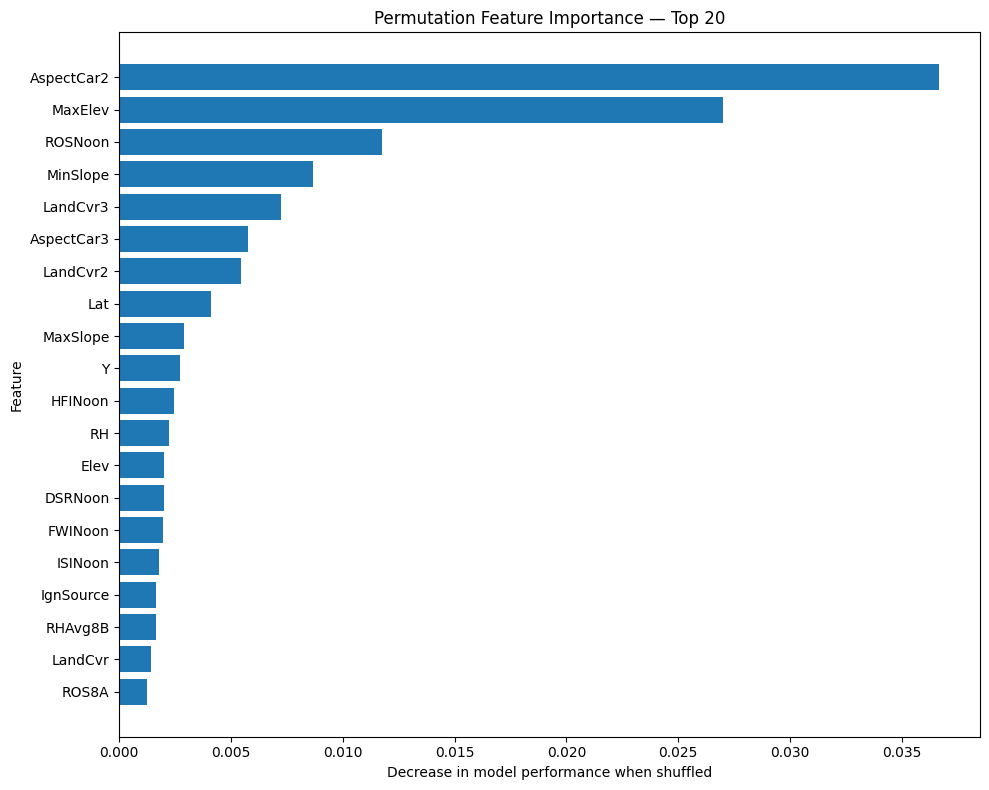

In [39]:

# ==========================================
# PERMUTATION FEATURE IMPORTANCE
# ==========================================

sample_size = min(15000, len(X_val_fs))

X_val_sample = X_val_fs.sample(
    n=sample_size,
    random_state=42
)

y_val_sample = y_val_fs.loc[X_val_sample.index]

importance = permutation_importance(
    feature_model,
    X_val_sample,
    np.log1p(y_val_sample),
    scoring="neg_root_mean_squared_error",
    n_repeats=2,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_val_sample.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

# Show unrounded values
pd.set_option("display.precision", 8)

display(importance_df)

# Plot the top 20 features
top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Decrease in model performance when shuffled")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — Top 20")
plt.tight_layout()
plt.show()


In [42]:

# ==========================================
# VALIDATION PERFORMANCE
# ==========================================

pred_log = feature_model.predict(X_val_fs)
pred_area = np.maximum(0, np.expm1(pred_log))

print("MAE:", mean_absolute_error(y_val_fs, pred_area))
print("RMSE:", np.sqrt(mean_squared_error(y_val_fs, pred_area)))
print("R2:", r2_score(y_val_fs, pred_area))


MAE: 0.9640247585809152
RMSE: 23.799067660373037
R2: 0.04873817019755655


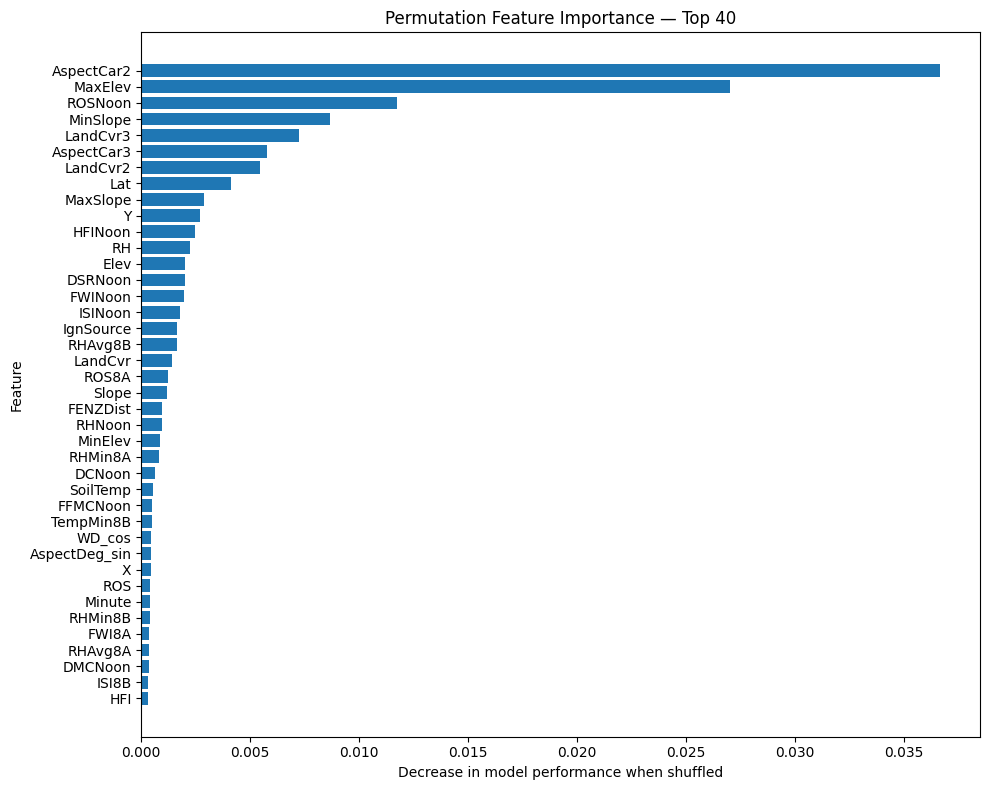

In [44]:
top_features = importance_df.head(40).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Decrease in model performance when shuffled")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — Top 40")
plt.tight_layout()
plt.show()